# 数据读取

## 盘点数据表

In [6]:
from pathlib import Path
import pandas as pd

In [7]:
cwd = Path.cwd()
project_dir = cwd.parent if cwd.name == "notebooks" else cwd
data_dir = project_dir/"data"/"raw"

In [8]:
csv_files = sorted(data_dir.glob("*.csv"))

In [9]:
if not csv_files:
    raise FileNotFoundError(
        f"没有找到 CSV 文件，请检查目录：{data_dir}"
    )

In [10]:
print(f"项目目录：{project_dir}")
print(f"发现 {len(csv_files)} 个 CSV 文件\n")

项目目录：/Users/huawu/Desktop/揾工/实习准备/olist-ecommerce-analysis
发现 9 个 CSV 文件



In [11]:
for file in csv_files:
    df = pd.read_csv(file, nrows=5)
    print(f"文件名：{file.name}")
    print(f"字段数：{len(df.columns)}")
    print(f"字段名：{df.columns.tolist()}")
    print(f"文件大小：{file.stat().st_size / 1024**2:.2f} MB")
    print("-" * 70)

文件名：olist_customers_dataset.csv
字段数：5
字段名：['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
文件大小：8.62 MB
----------------------------------------------------------------------
文件名：olist_geolocation_dataset.csv
字段数：5
字段名：['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']
文件大小：58.44 MB
----------------------------------------------------------------------
文件名：olist_order_items_dataset.csv
字段数：7
字段名：['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
文件大小：14.72 MB
----------------------------------------------------------------------
文件名：olist_order_payments_dataset.csv
字段数：5
字段名：['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
文件大小：5.51 MB
----------------------------------------------------------------------
文件名：olist_order_reviews_dataset.csv
字段数：7
字段名：['review_id', 'order_id', 're

## 数据审计

In [12]:
# 读取全部 CSV
tables = {
    file.stem: pd.read_csv(file)
    for file in csv_files
}

# 1. 查看每张表的行数、列数
for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} 行, {df.shape[1]} 列")

olist_customers_dataset: 99,441 行, 5 列
olist_geolocation_dataset: 1,000,163 行, 5 列
olist_order_items_dataset: 112,650 行, 7 列
olist_order_payments_dataset: 103,886 行, 5 列
olist_order_reviews_dataset: 99,224 行, 7 列
olist_orders_dataset: 99,441 行, 8 列
olist_products_dataset: 32,951 行, 9 列
olist_sellers_dataset: 3,095 行, 4 列
product_category_name_translation: 71 行, 2 列


In [13]:
# 2. 检查缺失值和完全重复行
for name, df in tables.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]

    print(f"\n{name}")
    print("完全重复行数：", df.duplicated().sum())

    if missing.empty:
        print("缺失值：无")
    else:
        print("缺失值：")
        print(missing.sort_values(ascending=False))


olist_customers_dataset
完全重复行数： 0
缺失值：无

olist_geolocation_dataset
完全重复行数： 261831
缺失值：无

olist_order_items_dataset
完全重复行数： 0
缺失值：无

olist_order_payments_dataset
完全重复行数： 0
缺失值：无

olist_order_reviews_dataset
完全重复行数： 0
缺失值：
review_comment_title      87656
review_comment_message    58247
dtype: int64

olist_orders_dataset
完全重复行数： 0
缺失值：
order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
dtype: int64

olist_products_dataset
完全重复行数： 0
缺失值：
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

olist_sellers_dataset
完全重复行数： 0
缺失值：无

product_category_name_translation
完全重复行数： 0
缺失值：无


## 检查主键

In [14]:
# 每张表的候选主键
primary_keys = {
    "olist_customers_dataset": ["customer_id"],
    "olist_orders_dataset": ["order_id"],
    "olist_order_items_dataset": ["order_id", "order_item_id"],
    "olist_order_payments_dataset": ["order_id", "payment_sequential"],
    "olist_order_reviews_dataset": ["review_id"],
    "olist_products_dataset": ["product_id"],
    "olist_sellers_dataset": ["seller_id"],
    "product_category_name_translation": ["product_category_name"],
}

for table_name, keys in primary_keys.items():
    df = tables[table_name]

    duplicate_count = df.duplicated(subset=keys).sum()
    missing_count = df[keys].isna().any(axis=1).sum()

    print(f"\n表：{table_name}")
    print(f"候选主键：{keys}")
    print(f"主键重复行数：{duplicate_count}")
    print(f"主键缺失行数：{missing_count}")


表：olist_customers_dataset
候选主键：['customer_id']
主键重复行数：0
主键缺失行数：0

表：olist_orders_dataset
候选主键：['order_id']
主键重复行数：0
主键缺失行数：0

表：olist_order_items_dataset
候选主键：['order_id', 'order_item_id']
主键重复行数：0
主键缺失行数：0

表：olist_order_payments_dataset
候选主键：['order_id', 'payment_sequential']
主键重复行数：0
主键缺失行数：0

表：olist_order_reviews_dataset
候选主键：['review_id']
主键重复行数：814
主键缺失行数：0

表：olist_products_dataset
候选主键：['product_id']
主键重复行数：0
主键缺失行数：0

表：olist_sellers_dataset
候选主键：['seller_id']
主键重复行数：0
主键缺失行数：0

表：product_category_name_translation
候选主键：['product_category_name']
主键重复行数：0
主键缺失行数：0


In [18]:
from itertools import combinations

reviews = tables["olist_order_reviews_dataset"]

# 检查单字段候选键
columns = reviews.columns.tolist()

print("一、单字段检查")
for col in columns:
    duplicate_count = reviews.duplicated(subset=[col]).sum()
    missing_count = reviews[col].isna().sum()

    print(
        f"{col:30s} "
        f"重复行数={duplicate_count:5d}, "
        f"缺失值数={missing_count:5d}"
    )

# 检查双字段组合
print("\n二、双字段组合检查")
for col1, col2 in combinations(columns, 2):
    keys = [col1, col2]
    duplicate_count = reviews.duplicated(subset=keys).sum()
    missing_count = reviews[keys].isna().any(axis=1).sum()

    if duplicate_count == 0:
        print(
            f"可能唯一：{keys}, "
            f"组合缺失行数={missing_count}"
        )

一、单字段检查
review_id                      重复行数=  814, 缺失值数=    0
order_id                       重复行数=  551, 缺失值数=    0
review_score                   重复行数=99219, 缺失值数=    0
review_comment_title           重复行数=94696, 缺失值数=87656
review_comment_message         重复行数=63064, 缺失值数=58247
review_creation_date           重复行数=98588, 缺失值数=    0
review_answer_timestamp        重复行数=  976, 缺失值数=    0

二、双字段组合检查
可能唯一：['review_id', 'order_id'], 组合缺失行数=0
可能唯一：['order_id', 'review_answer_timestamp'], 组合缺失行数=0


# 数据探索

In [19]:
orders = tables["olist_orders_dataset"]

status_summary = (
    orders["order_status"]
    .value_counts(dropna=False)
    .rename_axis("order_status")
    .reset_index(name="order_count")
)

status_summary["percentage"] = (
    status_summary["order_count"] / len(orders) * 100
).round(2)

status_summary

,order_status,order_count,percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [20]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

monthly_orders = (
    orders
    .dropna(subset=["order_purchase_timestamp"])
    .assign(
        order_month=lambda df: (
            df["order_purchase_timestamp"].dt.to_period("M")
        )
    )
    .groupby("order_month")
    .size()
    .reset_index(name="order_count")
)

monthly_orders

,order_month,order_count
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


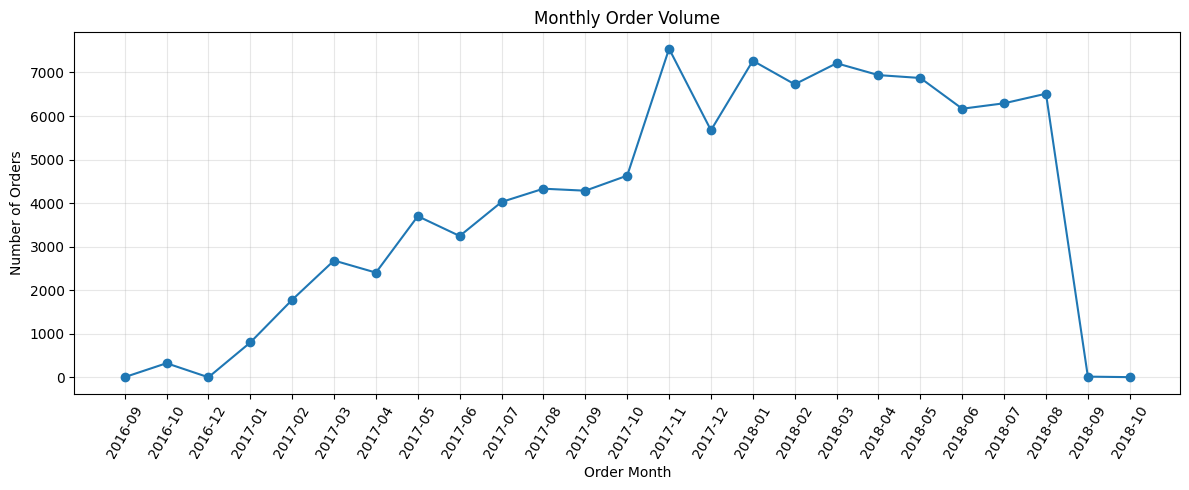

In [21]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plot_data = monthly_orders.copy()
plot_data["order_month"] = (
    plot_data["order_month"].astype(str)
)

plt.figure(figsize=(12, 5))
plt.plot(
    plot_data["order_month"],
    plot_data["order_count"],
    marker="o"
)

plt.title("Monthly Order Volume")
plt.xlabel("Order Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
print("最早下单时间：", orders["order_purchase_timestamp"].min())
print("最晚下单时间：", orders["order_purchase_timestamp"].max())
print("下单时间缺失数：", orders["order_purchase_timestamp"].isna().sum())

最早下单时间： 2016-09-04 21:15:19
最晚下单时间： 2018-10-17 17:30:18
下单时间缺失数： 0


## 订单是否按时交付？

In [23]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

delivered_orders["order_delivered_customer_date"] = pd.to_datetime(
    delivered_orders["order_delivered_customer_date"],
    errors="coerce"
)

delivered_orders["order_estimated_delivery_date"] = pd.to_datetime(
    delivered_orders["order_estimated_delivery_date"],
    errors="coerce"
)

delivered_orders = delivered_orders.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

delivered_orders["delivery_delay_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivery_summary = pd.Series({
    "有效已交付订单数": len(delivered_orders),
    "按时或提前交付比例(%)": (
        delivered_orders["delivery_delay_days"].le(0).mean() * 100
    ).round(2),
    "延迟交付比例(%)": (
        delivered_orders["delivery_delay_days"].gt(0).mean() * 100
    ).round(2),
    "平均交付偏差(天)": (
        delivered_orders["delivery_delay_days"].mean()
    ).round(2),
    "交付偏差中位数(天)": (
        delivered_orders["delivery_delay_days"].median()
    ).round(2)
})

delivery_summary

有效已交付订单数        96470.00
按时或提前交付比例(%)       91.89
延迟交付比例(%)           8.11
平均交付偏差(天)         -11.18
交付偏差中位数(天)        -11.95
dtype: float64

In [24]:
monthly_delivery = delivered_orders.copy()

monthly_delivery["order_month"] = (
    monthly_delivery["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_delivery["is_delayed"] = (
    monthly_delivery["delivery_delay_days"] > 0
)

monthly_delay_summary = (
    monthly_delivery
    .groupby("order_month")
    .agg(
        delivered_orders=("order_id", "count"),
        delayed_orders=("is_delayed", "sum"),
        delay_rate=("is_delayed", "mean"),
        avg_delay_days=("delivery_delay_days", "mean")
    )
    .reset_index()
)

monthly_delay_summary["delay_rate"] = (
    monthly_delay_summary["delay_rate"] * 100
).round(2)

monthly_delay_summary["avg_delay_days"] = (
    monthly_delay_summary["avg_delay_days"].round(2)
)

monthly_delay_summary

,order_month,delivered_orders,delayed_orders,delay_rate,avg_delay_days
0,2016-09,1,1,100.00,36.32
1,2016-10,265,3,1.13,-36.08
2,2016-12,1,0,0.00,-21.34
3,2017-01,750,23,3.07,-26.86
4,2017-02,1653,53,3.21,-18.68
5,2017-03,2546,142,5.58,-11.78
6,2017-04,2303,181,7.86,-12.43
7,2017-05,3545,128,3.61,-12.96
8,2017-06,3135,121,3.86,-12.01
9,2017-07,3872,133,3.43,-11.72


In [25]:
delay_severity = (
    delivered_orders[
        delivered_orders["delivery_delay_days"] > 0
    ]
    .assign(
        order_month=lambda df: (
            df["order_purchase_timestamp"].dt.to_period("M").astype(str)
        )
    )
    .groupby("order_month")
    .agg(
        delayed_orders=("order_id", "count"),
        avg_late_days=("delivery_delay_days", "mean"),
        median_late_days=("delivery_delay_days", "median")
    )
    .reset_index()
)

delay_severity["avg_late_days"] = (
    delay_severity["avg_late_days"].round(2)
)
delay_severity["median_late_days"] = (
    delay_severity["median_late_days"].round(2)
)

delay_severity[
    delay_severity["order_month"].isin(
        ["2017-11", "2018-02", "2018-03", "2018-04", "2018-06"]
    )
]

,order_month,delayed_orders,avg_late_days,median_late_days
12,2017-11,1043,10.39,6.83
15,2018-02,1048,11.82,7.75
16,2018-03,1496,9.58,6.89
17,2018-04,361,9.51,5.87
19,2018-06,83,12.14,6.84


# 业务探究

## 平台交易情况

In [26]:
import pandas as pd

orders = tables["olist_orders_dataset"]
items = tables["olist_order_items_dataset"]

# 仅保留已交付订单，先建立实际完成交易的经营基线
delivered_orders = orders.loc[
    orders["order_status"] == "delivered",
    ["order_id", "order_purchase_timestamp"]
].copy()

delivered_orders["order_purchase_timestamp"] = pd.to_datetime(
    delivered_orders["order_purchase_timestamp"],
    errors="coerce"
)

# 按订单汇总商品金额和运费
order_amounts = (
    items.groupby("order_id")
    .agg(
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
)

# 关联订单与金额
transaction_data = delivered_orders.merge(
    order_amounts,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# 计算整体经营指标
summary = pd.Series({
    "已交付订单数": transaction_data["order_id"].nunique(),
    "商品销售额": transaction_data["merchandise_value"].sum(),
    "运费总额": transaction_data["freight_value"].sum(),
    "平均每单商品金额": transaction_data["merchandise_value"].mean(),
    "平均每单运费": transaction_data["freight_value"].mean()
})

summary

已交付订单数      9.647800e+04
商品销售额       1.322150e+07
运费总额        2.198276e+06
平均每单商品金额    1.370416e+02
平均每单运费      2.278525e+01
dtype: float64

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

orders = tables["olist_orders_dataset"]
items = tables["olist_order_items_dataset"]

# 1. 筛选已交付订单
delivered_orders = orders.loc[
    orders["order_status"] == "delivered",
    ["order_id", "order_purchase_timestamp"]
].copy()

delivered_orders["order_purchase_timestamp"] = pd.to_datetime(
    delivered_orders["order_purchase_timestamp"],
    errors="coerce"
)

# 2. 按订单汇总商品金额
order_amounts = (
    items.groupby("order_id")
    .agg(
        merchandise_value=("price", "sum")
    )
    .reset_index()
)

# 3. 合并订单与金额
transaction_data = delivered_orders.merge(
    order_amounts,
    on="order_id",
    how="left",
    validate="one_to_one"
).dropna(subset=["order_purchase_timestamp", "merchandise_value"])

# 4. 按下单月份汇总
transaction_data["order_month"] = (
    transaction_data["order_purchase_timestamp"].dt.to_period("M")
)

monthly_trade = (
    transaction_data
    .groupby("order_month")
    .agg(
        order_count=("order_id", "nunique"),
        merchandise_sales=("merchandise_value", "sum"),
        avg_order_value=("merchandise_value", "mean")
    )
    .reset_index()
)

monthly_trade["avg_order_value"] = (
    monthly_trade["avg_order_value"].round(2)
)

monthly_trade

,order_month,order_count,merchandise_sales,avg_order_value
0,2016-09,1,134.97,134.97
1,2016-10,265,40325.11,152.17
2,2016-12,1,10.90,10.90
3,2017-01,750,111798.36,149.06
4,2017-02,1653,234223.40,141.70
5,2017-03,2546,359198.85,141.08
6,2017-04,2303,340669.68,147.92
7,2017-05,3546,489338.25,138.00
8,2017-06,3135,421923.37,134.58
9,2017-07,3872,481604.52,124.38


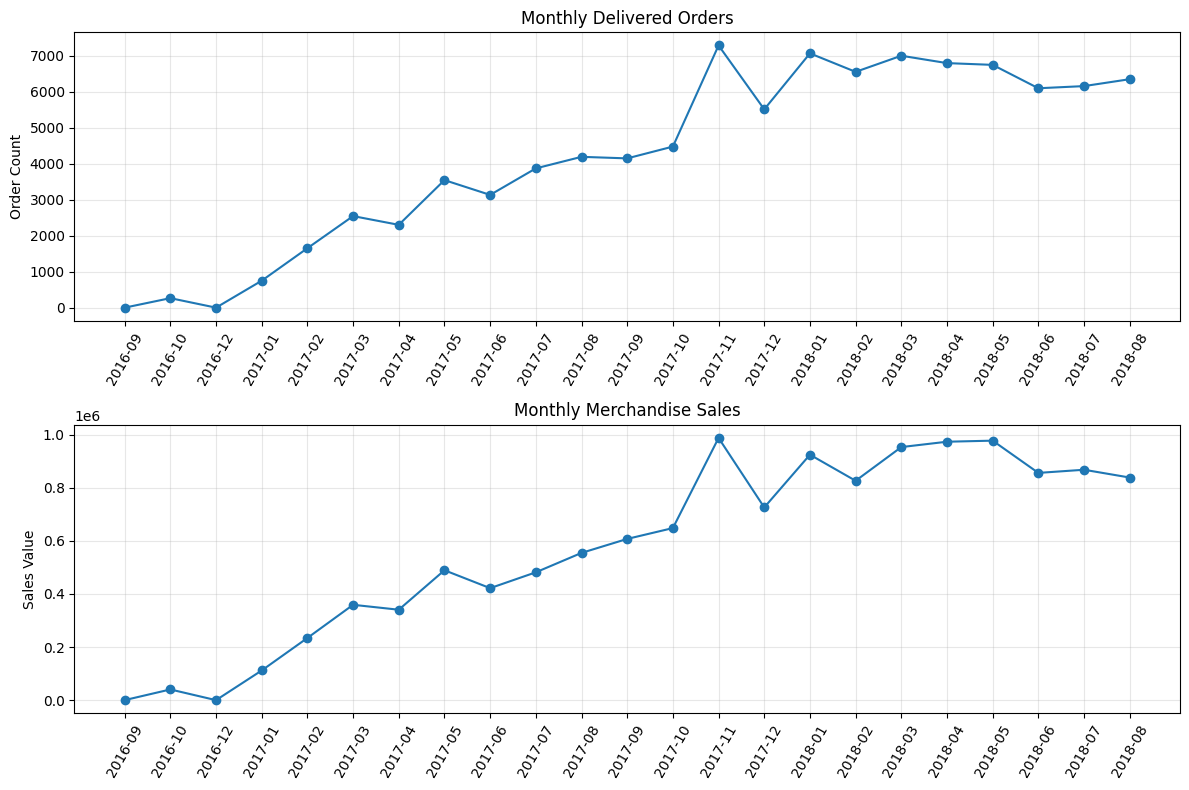

In [28]:
plot_data = monthly_trade.copy()
plot_data["order_month"] = plot_data["order_month"].astype(str)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(
    plot_data["order_month"],
    plot_data["order_count"],
    marker="o"
)
axes[0].set_title("Monthly Delivered Orders")
axes[0].set_ylabel("Order Count")
axes[0].tick_params(axis="x", rotation=60)
axes[0].grid(alpha=0.3)

axes[1].plot(
    plot_data["order_month"],
    plot_data["merchandise_sales"],
    marker="o"
)
axes[1].set_title("Monthly Merchandise Sales")
axes[1].set_ylabel("Sales Value")
axes[1].tick_params(axis="x", rotation=60)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 用户体验情况

,review_score,review_count,percentage
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78


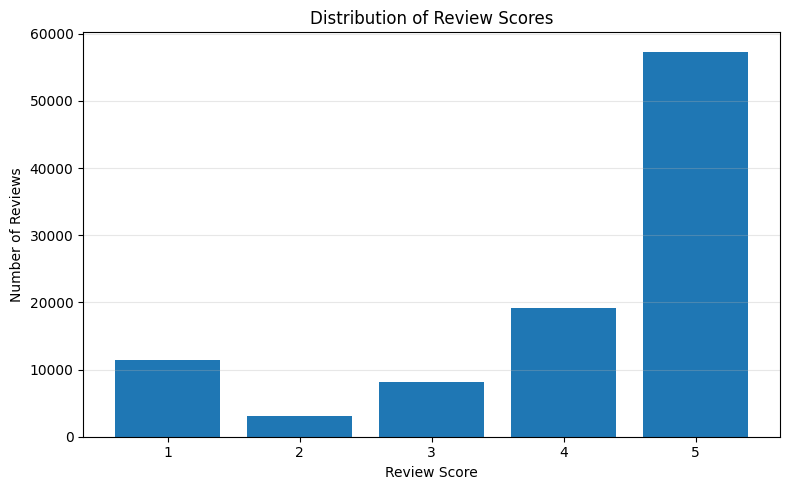

平均评分： 4.09
低分评价占比（1–2分）： 14.69 %


In [30]:
reviews = tables["olist_order_reviews_dataset"]

# 评分分布
score_summary = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .rename_axis("review_score")
    .reset_index(name="review_count")
)

score_summary["percentage"] = (
    score_summary["review_count"] / score_summary["review_count"].sum() * 100
).round(2)

display(score_summary)

# 评分分布图
plt.figure(figsize=(8, 5))
plt.bar(
    score_summary["review_score"].astype(str),
    score_summary["review_count"]
)
plt.title("Distribution of Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("平均评分：", reviews["review_score"].mean().round(2))
print(
    "低分评价占比（1–2分）：",
    (reviews["review_score"].isin([1, 2]).mean() * 100).round(2),
    "%"
)